# Chapter 23 — Discrete State Markov Models (Markov Chains & HMMs)
> *Reference: Paraphrased from David Barber's Bayesian Reasoning and Machine Learning (Chapter 23: Discrete-State Markov Models) & Bishop PRML Chapter 13.*

Many real-world processes generate sequences of observations ordered in time or space (e.g., text, speech, genomic sequences, financial records, weather). When dealing with sequential data, the assumption that observations are independent and identically distributed (i.i.d.) fails.

This notebook demonstrates:
1. **Discrete-Time Markov Chains (`MarkovChain`)**:
   - First-order Markov property: $P(S_t \mid S_{t-1}, \dots, S_0) = P(S_t \mid S_{t-1})$
   - Multi-step transition matrices $T^n$
   - Stationary distributions $\pi T = \pi$
   - Trajectory simulation
   - Absorbing chains (fundamental matrix $N = (I - Q)^{-1}$, absorption probabilities $B = NR$, and expected time to absorption)
   - Transition diagram plotting
2. **Hidden Markov Models (`HMM`)**:
   - Hidden state sequence $Z_{1:T}$ and observable emissions $X_{1:T}$
   - The classic **Dishonest Casino** benchmark (Fair vs. Loaded die)
   - Sequence marginal likelihood $P(X_{1:T})$ via scaled Forward algorithm
   - Real-time online **Filtering** $P(Z_t \mid X_{1:t})$
   - Offline retrospective **Smoothing** $P(Z_t \mid X_{1:T})$ via Forward-Backward
   - Most probable hidden trajectory via **Viterbi Decoding** (dynamic programming in log-space)
   - Posterior probability curves and decoded sequence visualization
3. **Bridging to Bayesian Networks**:
   - Unrolling temporal chains into exact `BayesianNetwork` DAGs (`.to_bayesian_network(n_steps)`).

In [1]:
import set_paths
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from probability.discrete import Discrete, Conditional, BayesianNetwork, MarkovChain, HMM
%matplotlib inline

## Part 1: Discrete-Time Markov Chains (`MarkovChain`)

### 1.1 Weather Forecasting (Two-State Markov Chain)

Consider a simple weather model with states $\mathcal{S} = \{\text{Sunny}, \text{Rainy}\}$:
- If today is Sunny, tomorrow is Sunny with probability 0.8 and Rainy with probability 0.2.
- If today is Rainy, tomorrow is Sunny with probability 0.4 and Rainy with probability 0.6.

In [2]:
weather_transitions = pd.DataFrame([
    [0.80, 0.20],
    [0.40, 0.60]
], index=['Sunny', 'Rainy'], columns=['Sunny', 'Rainy'])

weather_mc = MarkovChain(
    transitions=weather_transitions,
    initial_distribution={'Sunny': 1.0, 'Rainy': 0.0}
)
weather_mc

MarkovChain(states=['Sunny', 'Rainy'], n_states=2)

### 1.2 Transition Diagram

We can inspect the state transition graph using `.draw()`:

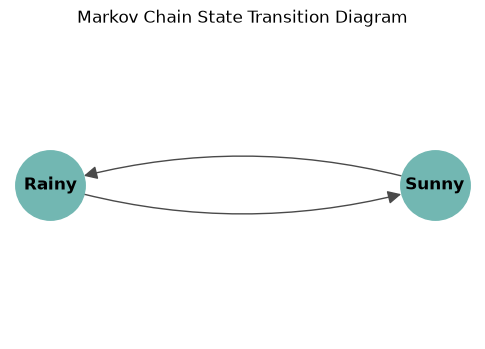

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
weather_mc.draw(ax=ax, node_color='#72B7B2', font_size=12)
plt.show()

### 1.3 Multi-Step Predictions & Stationary Distribution

The probability of transitioning between states after $n$ steps is given by powers of the transition matrix, $T^n$.
As $n \to \infty$, an ergodic chain converges to its unique **stationary distribution** $\pi$ satisfying:
$$\pi T = \pi, \quad \sum_{i} \pi_i = 1$$

Analytically for our 2-state weather matrix:
$$\pi_S = 0.8 \pi_S + 0.4 \pi_R \implies 0.2 \pi_S = 0.4 \pi_R \implies \pi_S = 2\pi_R$$
Since $\pi_S + \pi_R = 1$, we have $\pi_S = \frac{2}{3} \approx 0.667$ and $\pi_R = \frac{1}{3} \approx 0.333$.

In [4]:
# Multi-step transition matrices
print('1-Step Transition Matrix T^1:')
display(weather_mc.n_step_transition_matrix(1))

print('2-Step Transition Matrix T^2:')
display(weather_mc.n_step_transition_matrix(2))

print('10-Step Transition Matrix T^10 (converged):')
display(weather_mc.n_step_transition_matrix(10))

# Exact stationary distribution
stat_dist = weather_mc.stationary_distribution()
print('\nStationary Distribution pi:')
print(f'P(Sunny) = {stat_dist.p(state="Sunny"):.4f}')
print(f'P(Rainy) = {stat_dist.p(state="Rainy"):.4f}')

1-Step Transition Matrix T^1:


,Sunny,Rainy
Sunny,0.8,0.2
Rainy,0.4,0.6


2-Step Transition Matrix T^2:


,Sunny,Rainy
Sunny,0.72,0.28
Rainy,0.56,0.44


10-Step Transition Matrix T^10 (converged):


,Sunny,Rainy
Sunny,0.666702,0.333298
Rainy,0.666597,0.333403



Stationary Distribution pi:
P(Sunny) = 0.6667
P(Rainy) = 0.3333


### 1.4 Simulating Trajectories

We can generate a synthetic realized trajectory across $N$ time steps using `.simulate()`:

First 20 simulated steps: [np.str_('Sunny'), np.str_('Sunny'), np.str_('Rainy'), np.str_('Rainy'), np.str_('Sunny'), np.str_('Rainy'), np.str_('Rainy'), np.str_('Rainy'), np.str_('Sunny'), np.str_('Sunny'), np.str_('Sunny'), np.str_('Rainy'), np.str_('Rainy'), np.str_('Rainy'), np.str_('Rainy'), np.str_('Sunny'), np.str_('Sunny'), np.str_('Sunny'), np.str_('Rainy'), np.str_('Rainy')]


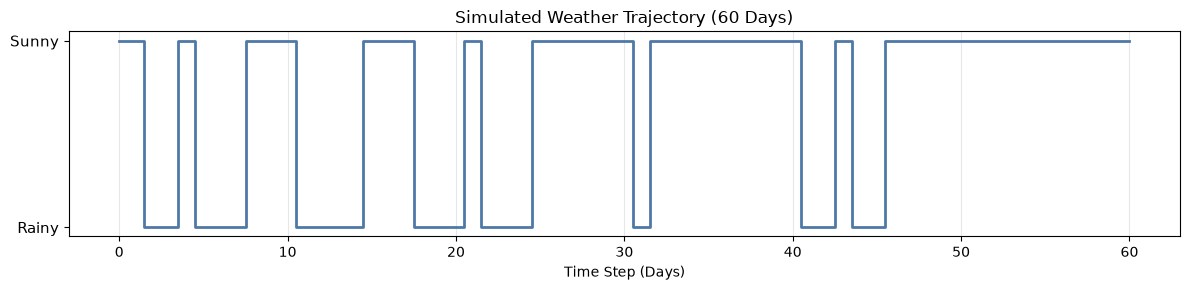

In [5]:
np.random.seed(42)
trajectory = weather_mc.simulate(n_steps=60, random_state=42)
print('First 20 simulated steps:', trajectory[:20])

# Plot simulated timeline
fig, ax = plt.subplots(figsize=(12, 3))
numeric_traj = [1 if s == 'Sunny' else 0 for s in trajectory]
ax.step(range(len(numeric_traj)), numeric_traj, where='mid', color='#4E79A7', lw=2)
ax.set_yticks([0, 1])
ax.set_yticklabels(['Rainy', 'Sunny'], fontsize=11)
ax.set_xlabel('Time Step (Days)')
ax.set_title('Simulated Weather Trajectory (60 Days)')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### 1.5 Absorbing Markov Chains (Gambler's Ruin)

An **absorbing Markov chain** has at least one absorbing state $s$ ($T_{ss} = 1$), and every transient state can eventually reach an absorbing state.

Consider a Gambler starting with money $k \in \{1, 2, 3, 4\}$ playing a fair coin toss game against a house with total capital $N = 5$:
- State 0: Ruin (Broke, Absorbing)
- States 1, 2, 3, 4: Active gambling (Transient, win +1 with $p=0.5$, lose -1 with $p=0.5$)
- State 5: Goal / Bankrupt the House (Absorbing)

Using the fundamental matrix $N = (I - Q)^{-1}$:
- $N_{ij}$: Expected number of visits to transient state $j$ before absorption when starting at $i$
- $t = N \mathbf{1}$: Expected time (number of steps) until absorption
- $B = NR$: Absorption probabilities (probability of ending in ruin vs. victory)

In [6]:
# 6 states: 0, 1, 2, 3, 4, 5
states = ['0', '1', '2', '3', '4', '5']
T = np.zeros((6, 6))
T[0, 0] = 1.0  # State 0 absorbing
T[5, 5] = 1.0  # State 5 absorbing
for i in range(1, 5):
    T[i, i - 1] = 0.5  # Lose $1
    T[i, i + 1] = 0.5  # Win $1

gambler_mc = MarkovChain(pd.DataFrame(T, index=states, columns=states))
print('Is absorbing chain:', gambler_mc.is_absorbing_chain())
print('Absorbing states:', gambler_mc.absorbing_states)
print('Transient states:', gambler_mc.transient_states)

Is absorbing chain: True
Absorbing states: ['0', '5']
Transient states: ['1', '2', '3', '4']


In [7]:
# Fundamental matrix N = (I - Q)^-1
N_mat = gambler_mc.fundamental_matrix()
print('Fundamental Matrix N:')
display(N_mat)

# Expected duration until absorption
exp_time = gambler_mc.expected_time_to_absorption()
print('\nExpected steps to absorption (ruin or victory) from each starting capital:')
display(exp_time)

# Absorption probabilities B = N * R
abs_prob = gambler_mc.absorption_probabilities()
print('\nAbsorption probabilities (ending broke vs. winning $5):')
display(abs_prob)

Fundamental Matrix N:


,1,2,3,4
1,1.6,1.2,0.8,0.4
2,1.2,2.4,1.6,0.8
3,0.8,1.6,2.4,1.2
4,0.4,0.8,1.2,1.6



Expected steps to absorption (ruin or victory) from each starting capital:


1    4.0
2    6.0
3    6.0
4    4.0
dtype: float64


Absorption probabilities (ending broke vs. winning $5):


,0,5
1,0.8,0.2
2,0.6,0.4
3,0.4,0.6
4,0.2,0.8


Notice how from starting capital $k$:
- Expected time to absorption is exactly $k(N - k)$: e.g. for $k=2, N=5$, time $= 2 \times 3 = 6$ steps!
- Probability of reaching the goal ($5) is exactly $k / N$: e.g. for $k=2$, prob $= 2/5 = 0.40$!

## Part 2: Hidden Markov Models (`HMM`)

In a **Hidden Markov Model**, the underlying state sequence $Z_1, Z_2, \dots, Z_T$ is latent (unobserved). At each time step $t$, the system emits an observation $X_t$ according to state-conditional emission probabilities $P(X_t \mid Z_t)$.

### 2.1 The Dishonest Casino Benchmark (BRML Example 23.1)

A casino uses two dice:
1. **Fair Die ($F$)**: All faces $1, \dots, 6$ have equal probability $\frac{1}{6} \approx 0.1667$.
2. **Loaded Die ($L$)**: Face $6$ occurs with probability $0.50$, and faces $1, \dots, 5$ each have probability $0.10$.

The croupier occasionally switches between the dice:
- $P(Z_t = F \mid Z_{t-1} = F) = 0.95, \quad P(Z_t = L \mid Z_{t-1} = F) = 0.05$
- $P(Z_t = L \mid Z_{t-1} = L) = 0.90, \quad P(Z_t = F \mid Z_{t-1} = L) = 0.10$
- Prior: $P(Z_1 = F) = 0.80, \quad P(Z_1 = L) = 0.20$

In [8]:
casino_states = ['Fair', 'Loaded']
casino_emissions = [1, 2, 3, 4, 5, 6]

transitions = pd.DataFrame([
    [0.95, 0.05],
    [0.10, 0.90]
], index=casino_states, columns=casino_states)

emissions = pd.DataFrame([
    [1.0 / 6] * 6,
    [0.10, 0.10, 0.10, 0.10, 0.10, 0.50]
], index=casino_states, columns=casino_emissions)

casino_hmm = HMM(
    states=casino_states,
    emissions=casino_emissions,
    transitions=transitions,
    emission_matrix=emissions,
    initial_distribution={'Fair': 0.8, 'Loaded': 0.2}
)
casino_hmm

HMM(states=['Fair', 'Loaded'], emissions=[1, 2, 3, 4, 5, 6])

### 2.2 Simulating the Casino Process

Let's sample 100 consecutive rolls from the croupier and observe the hidden state switches:

In [9]:
np.random.seed(123)
true_states, observed_rolls = casino_hmm.sample(n_steps=100, random_state=123)
print('First 30 true states:   ', ''.join(['F' if s == 'Fair' else 'L' for s in true_states[:30]]))
print('First 30 observed rolls:', observed_rolls[:30])

First 30 true states:    FFFFFFFFFFFFFFFFFFFFFFFFFFFFFF
First 30 observed rolls: [np.int64(1), np.int64(2), np.int64(5), np.int64(2), np.int64(6), np.int64(2), np.int64(2), np.int64(4), np.int64(2), np.int64(4), np.int64(1), np.int64(4), np.int64(1), np.int64(5), np.int64(4), np.int64(6), np.int64(6), np.int64(2), np.int64(6), np.int64(4), np.int64(4), np.int64(5), np.int64(2), np.int64(1), np.int64(3), np.int64(2), np.int64(3), np.int64(3), np.int64(4), np.int64(5)]


### 2.3 Likelihood of the Observation Sequence

Using Rabiner's scaled Forward algorithm, we can evaluate the exact log-likelihood $\ln P(X_{1:T})$ without numerical underflow:

In [10]:
log_lik = casino_hmm.log_likelihood(observed_rolls)
print(f'Total log-likelihood ln P(X_{{1:100}}) = {log_lik:.2f}')
print(f'Average log-likelihood per roll       = {log_lik / len(observed_rolls):.4f}')

Total log-likelihood ln P(X_{1:100}) = -178.94
Average log-likelihood per roll       = -1.7894


### 2.4 Online Filtering vs. Offline Smoothing

- **Filtering** $P(Z_t \mid x_{1:t})$: Uses only observations up to the current time step (causal / online).
- **Smoothing** $P(Z_t \mid x_{1:T})$: Uses all observations before and after step $t$ via the Backward pass (retrospective / offline).

Notice how smoothing provides cleaner, more confident estimates of when the loaded die was active!

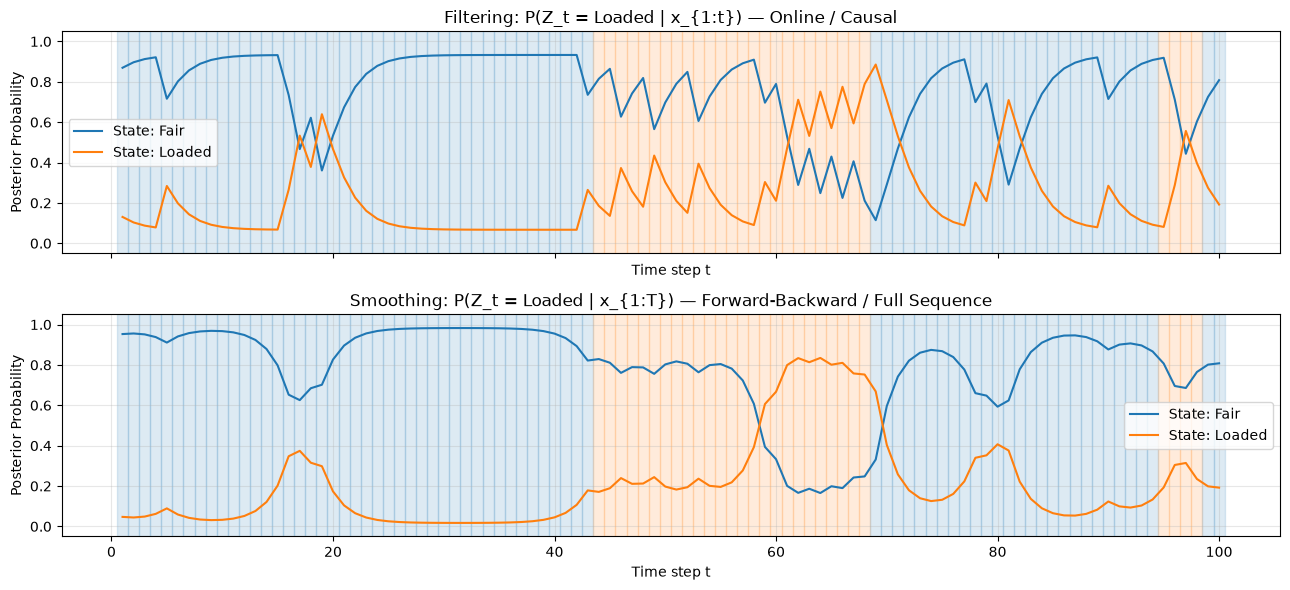

In [11]:
filtered_df = casino_hmm.filter(observed_rolls)
smoothed_df = casino_hmm.smooth(observed_rolls)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
# Filtered
casino_hmm.plot_states(observed_rolls, smoothed=False, true_states=true_states, ax=ax1)
ax1.set_title('Filtering: P(Z_t = Loaded | x_{1:t}) — Online / Causal', fontsize=12)
# Smoothed
casino_hmm.plot_states(observed_rolls, smoothed=True, true_states=true_states, ax=ax2)
ax2.set_title('Smoothing: P(Z_t = Loaded | x_{1:T}) — Forward-Backward / Full Sequence', fontsize=12)

plt.tight_layout()
plt.show()

### 2.5 Viterbi Decoding (Global Maximum a Posteriori Sequence)

Finding the single most probable sequence of hidden states $\arg\max_{z_{1:T}} P(z_{1:T} \mid x_{1:T})$ is solved globally by the dynamic programming **Viterbi algorithm** in log-space.

Let's compare the Viterbi decoded path against the ground truth hidden states:

Viterbi sequence log-probability: -184.48
Decoded vs. True State Agreement: 71.0% (71/100)


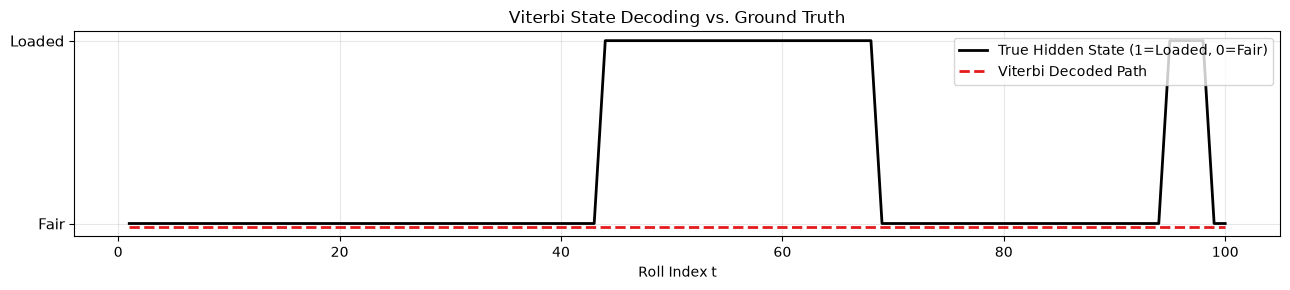

In [12]:
decoded_path, max_log_prob = casino_hmm.decode(observed_rolls)

# Compute accuracy
matches = sum(1 for true, dec in zip(true_states, decoded_path) if true == dec)
accuracy = matches / len(true_states)
print(f'Viterbi sequence log-probability: {max_log_prob:.2f}')
print(f'Decoded vs. True State Agreement: {accuracy * 100:.1f}% ({matches}/{len(true_states)})')

# Visual comparison
fig, ax = plt.subplots(figsize=(13, 3))
y_true = [1 if s == 'Loaded' else 0 for s in true_states]
y_viterbi = [0.98 if s == 'Loaded' else -0.02 for s in decoded_path]

ax.plot(range(1, 101), y_true, label='True Hidden State (1=Loaded, 0=Fair)', color='black', lw=2)
ax.plot(range(1, 101), y_viterbi, label='Viterbi Decoded Path', color='#E41A1C', linestyle='--', lw=2)
ax.set_yticks([0, 1])
ax.set_yticklabels(['Fair', 'Loaded'], fontsize=11)
ax.set_xlabel('Roll Index t')
ax.set_title('Viterbi State Decoding vs. Ground Truth')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Part 3: Temporal Unrolling into Bayesian Networks

Both `MarkovChain` and `HMM` seamlessly unroll into a `BayesianNetwork` DAG via `.to_bayesian_network(n_steps)`.
This enables exact graph-based reasoning, d-separation queries, and conditional independence tests on sequential models.

In [13]:
unrolled_bn = casino_hmm.to_bayesian_network(n_steps=3)
print('Unrolled HMM Bayesian Network nodes:', unrolled_bn.nodes)

# Verify the Markov property: X_0 is conditionally independent of X_2 given Z_1
is_indep = unrolled_bn.is_independent('X_0', 'X_2', given=['Z_1'])
print(f'Is X_0 independent of X_2 given Z_1? {is_indep}')

# Exact variable elimination query on the unrolled network:
# If rolls at t=0 and t=1 are both 6, what is the posterior probability that Z_1 was Loaded?
q_res = unrolled_bn.query('Z_1', evidence={'X_0': 6, 'X_1': 6})
print('\nP(Z_1 | X_0=6, X_1=6):')
print(f'P(Loaded) = {q_res.p(Z_1="Loaded"):.4f}')
print(f'P(Fair)   = {q_res.p(Z_1="Fair"):.4f}')

Unrolled HMM Bayesian Network nodes: ['Z_0', 'X_0', 'Z_1', 'X_1', 'Z_2', 'X_2', 'Z_3', 'X_3']
Is X_0 independent of X_2 given Z_1? True

P(Z_1 | X_0=6, X_1=6):
P(Loaded) = 0.6797
P(Fair)   = 0.3203


## Summary

In this notebook, we demonstrated:
- **`MarkovChain`**: Computing $n$-step transitions, solving for stationary distributions, calculating fundamental matrices for absorbing chains, and simulating trajectories.
- **`HMM`**: The Dishonest Casino benchmark, exact scaled sequence likelihood, online causal filtering vs. retrospective full-sequence smoothing, and dynamic programming Viterbi decoding.
- **Temporal Unrolling**: Converting sequential models directly into Directed Acyclic Graphs with `BayesianNetwork`.